<a href="https://colab.research.google.com/github/huiyzhao/MSSP607/blob/main/WeeklyModules/Week10/huiyzhao(chatgpt_improvement).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
REPOSITORY_NAME = "MSSP607"
REPOSITORY_URL = "https://github.com/huiyzhao/MSSP607.git"

if not Path(REPOSITORY_NAME).exists():
    subprocess.run(
        ["git", "clone", REPOSITORY_URL],
        check=True
    )

subprocess.run(
    ["git", "-C", REPOSITORY_NAME, "pull"],
    check=True
)

print(f"Repository ready: {Path(REPOSITORY_NAME).resolve()}")

Repository ready: /content/MSSP607


In [3]:
DATA_FILE = Path(REPOSITORY_NAME) / "WeeklyModules/Week08/InternetSales.csv"

sales_df = pd.read_csv(
    DATA_FILE,
    encoding="latin1",
    low_memory=False,
    parse_dates=["OrderDate"]
)

print(f"Dataset shape: {sales_df.shape}")
sales_df.head()

Dataset shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,2011-01-19,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,2013-01-18,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,2013-01-18,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,2013-05-03,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,2013-05-03,5/15/2013,5/10/2013


In [4]:
top_products = (
    sales_df.groupby("EnglishProductName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_products

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1.373470e+06
"Mountain-200 Black, 42",1.363142e+06
"Mountain-200 Silver, 38",1.339463e+06
"Mountain-200 Silver, 46",1.301100e+06
"Mountain-200 Black, 38",1.294866e+06


In [5]:
yearly_sales = (
    sales_df.groupby(sales_df["OrderDate"].dt.year)["SalesAmount"]
    .sum()
)

yearly_sales

,SalesAmount
OrderDate,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


In [6]:
yearly_summary = (
    sales_df.groupby(sales_df["OrderDate"].dt.year)["OrderDate"]
    .agg(start_date="min", end_date="max", transaction_count="count")
)

yearly_summary

,start_date,end_date,transaction_count
OrderDate,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [7]:
analysis_sales = sales_df.loc[
    (sales_df["OrderDate"] >= "2011-01-01")
    & (sales_df["OrderDate"] < "2014-01-01")
].copy()

monthly_sales = (
    analysis_sales.set_index("OrderDate")["SalesAmount"]
    .resample("MS")
    .sum()
)

monthly_sales.head()

,SalesAmount
OrderDate,
2011-01-01,469823.9148
2011-02-01,466334.9030
2011-03-01,485198.6594
2011-04-01,502073.8458
2011-05-01,561681.4758


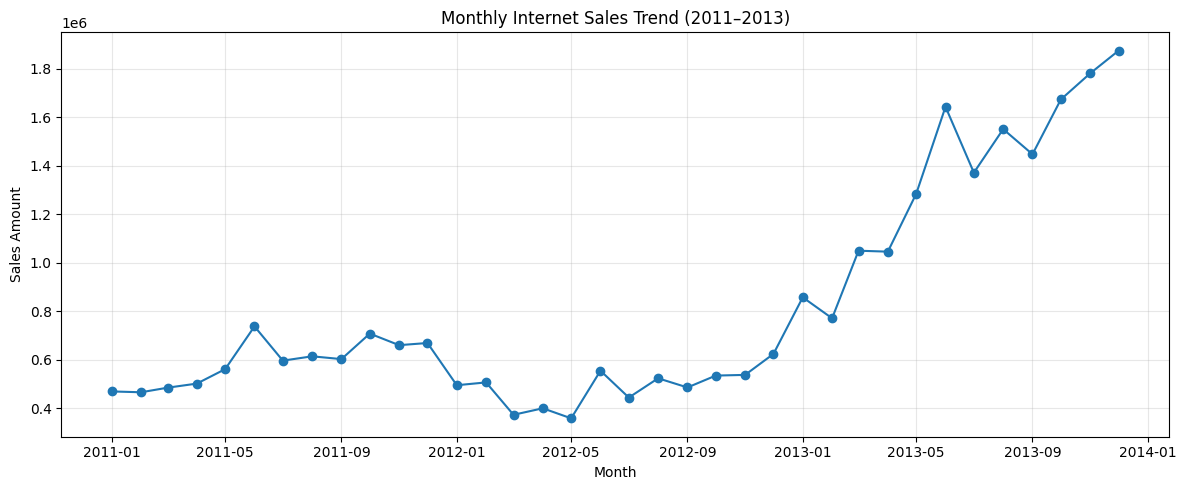

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales, marker="o")

plt.title("Monthly Internet Sales Trend (2011–2013)")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
sales_model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

five_year_forecast = sales_model.forecast(60)

five_year_forecast.head()

,0
2014-01-01,1.949116e+06
2014-02-01,1.996462e+06
2014-03-01,2.142314e+06
2014-04-01,2.235284e+06
2014-05-01,2.396946e+06


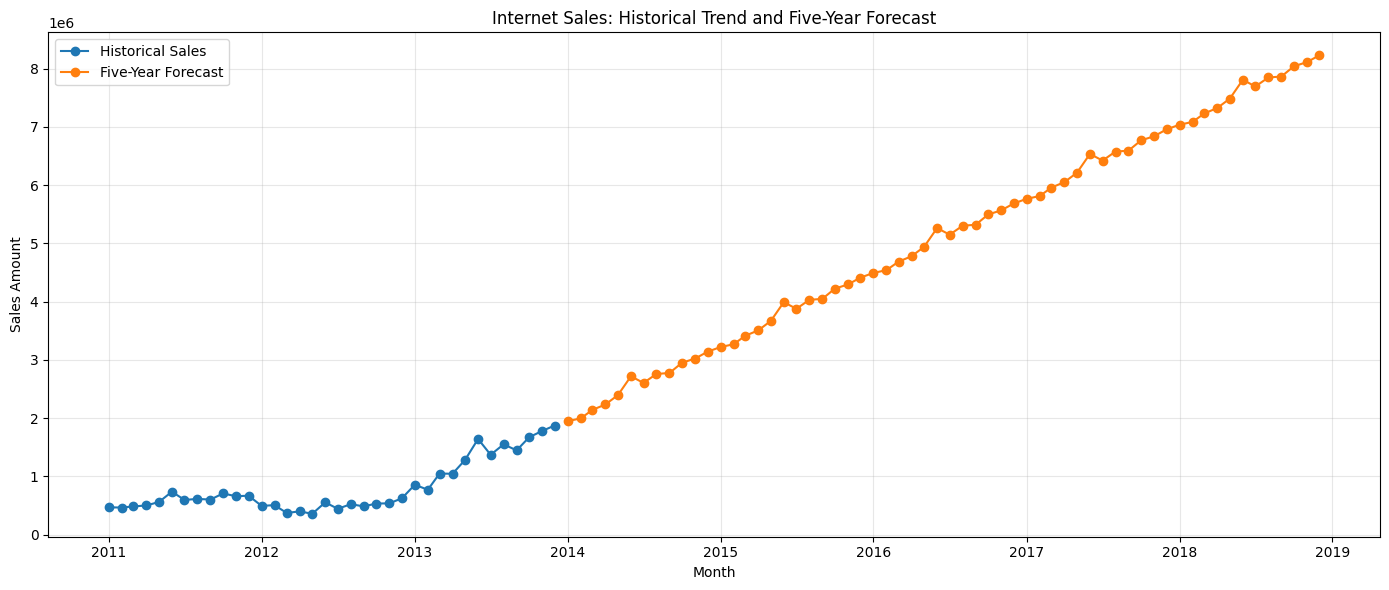

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales,
    label="Historical Sales",
    marker="o"
)

plt.plot(
    five_year_forecast,
    label="Five-Year Forecast",
    color="tab:orange",
    marker="o"
)

plt.title("Internet Sales: Historical Trend and Five-Year Forecast")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()